# Session 9 — a loss harness you can trust

**ERA V5 · Session 9: Loss Functions & Output Heads**

A small GPT (about 30M parameters) on Tiny Shakespeare. The point is not the model. It is the few lines between
`model(tokens)` and the loss number, where bugs stay quiet: each step is made visible and then checked.

| Part | What it shows |
|---|---|
| **1** | every tensor shape · the shift, read as strings · padding mask · document-boundary mask · perplexity of an untrained model · tied vs untied head · peak memory of ordinary vs hand-written chunked cross-entropy |
| **2** | a second output head that predicts token *t+2* |
| **3** | the bug the brief warns about: a missing shift, and the beautiful loss curve it draws |

Runs top to bottom on CPU or GPU. In Colab: *Runtime → Run all*.

In [1]:
import importlib.util, subprocess, sys
if importlib.util.find_spec("tiktoken") is None:          # Colab does not always ship it
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "tiktoken"], check=True)

import math, os, json, time, urllib.request
from dataclasses import dataclass
import torch, torch.nn as nn, torch.nn.functional as F
import tiktoken
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_num_threads(os.cpu_count())
os.makedirs("figures", exist_ok=True)
RESULTS = {}                                               # every reported number lands here
print(f"device: {device} | torch {torch.__version__}")

device: cuda | torch 2.11.0+cu130


## 0. Data

Tiny Shakespeare (about 1.1M characters), tokenised with the GPT-2 tokenizer. Its vocabulary of **V = 50,257**
is large next to our width of 256. That makes the session's main point easy to see: the output head is the
expensive part.

In [2]:
URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
if not os.path.exists("input.txt"):
    urllib.request.urlretrieve(URL, "input.txt")
text = open("input.txt", encoding="utf-8").read()

enc = tiktoken.get_encoding("gpt2")
V   = enc.n_vocab                     # 50,257 tokens
EOT = enc.eot_token                   # 50,256  <|endoftext|>, GPT-2's only special token

ids = torch.tensor(enc.encode_ordinary(text), dtype=torch.long)
split = int(0.9 * len(ids))
train_ids, val_ids = ids[:split], ids[split:]
val_text = enc.decode(val_ids.tolist())

print(f"{len(text):,} characters -> {len(ids):,} tokens ({len(text) / len(ids):.2f} characters per token)")
print(f"train {len(train_ids):,} tokens | val {len(val_ids):,} tokens | vocabulary V = {V:,}")

1,115,394 characters -> 338,025 tokens (3.30 characters per token)
train 304,222 tokens | val 33,803 tokens | vocabulary V = 50,257


## 1. The model

A decoder-only transformer, built the way Section 2 of the lesson describes:

- **pre-norm**: `x = x + attention(norm(x))`, then `x = x + ffn(norm(x))`, so the residual path stays clean
- **RMSNorm** (scaling only, no centring)
- **SwiGLU** feed-forward: `down(silu(gate(h)) * up(h))`, with d_ff = 704 ≈ 8/3 × 256

`model(tokens)` returns **hidden states**, and the head is a separate step. That mirrors the brief:
`hidden = model(tokens); logits = output_head(hidden)`.

`rec(...)` records shapes during one traced forward pass (block 0 only, since the other blocks repeat it).

In [3]:
@dataclass
class Config:
    vocab_size: int = V
    block_size: int = 128      # T  - context length in tokens
    d_model: int = 256         # D  - numbers per token vector
    n_layer: int = 6
    n_head: int = 4            # H  - attention heads, each of width D/H = 64
    d_ff: int = 704            # F  - SwiGLU hidden width (8/3 x 256 = 683, rounded up to a multiple of 64)
    dropout: float = 0.1
    tie_weights: bool = False  # True: the output head reuses the input embedding table
    n_out_heads: int = 1       # 1: predict t+1 only.  2: also predict t+2 (Part 2)

TRACE = None                   # set to a list to record shapes during one forward pass
def rec(name, t, dims, meaning):
    if TRACE is not None:
        TRACE.append((name, tuple(t.shape), dims, meaning))


class Attention(nn.Module):
    def __init__(self, cfg, trace):
        super().__init__()
        self.h, self.dh, self.p, self.trace = cfg.n_head, cfg.d_model // cfg.n_head, cfg.dropout, trace
        self.qkv  = nn.Linear(cfg.d_model, 3 * cfg.d_model, bias=False)
        self.proj = nn.Linear(cfg.d_model, cfg.d_model, bias=False)
        self.proj.residual = True

    def forward(self, x, attn_mask=None):
        B, T, D = x.shape
        qkv = self.qkv(x)
        q, k, v = (t.view(B, T, self.h, self.dh).transpose(1, 2) for t in qkv.split(D, dim=2))
        if self.trace:
            rec("qkv projection", qkv, "B, T, 3D", "query, key and value for every token, side by side")
            rec("queries (= keys = values)", q, "B, H, T, Dh", "split into H heads, each sees T positions with Dh numbers")
            rec("attention scores", q @ k.transpose(-2, -1), "B, H, T, T",
                "per head: how much each position looks at every other (printed only; SDPA never stores it)")
        drop = self.p if self.training else 0.0
        if attn_mask is None:
            y = F.scaled_dot_product_attention(q, k, v, is_causal=True, dropout_p=drop)
        else:                                           # custom mask, e.g. document-aware (Section 1.7)
            y = F.scaled_dot_product_attention(q, k, v, attn_mask=attn_mask, dropout_p=drop)
        y = y.transpose(1, 2).reshape(B, T, D)
        if self.trace:
            rec("heads merged", y, "B, T, D", "the H head outputs glued back into one D-vector per token")
        return self.proj(y)


class SwiGLU(nn.Module):
    def __init__(self, cfg, trace):
        super().__init__()
        self.trace = trace
        self.gate = nn.Linear(cfg.d_model, cfg.d_ff, bias=False)
        self.up   = nn.Linear(cfg.d_model, cfg.d_ff, bias=False)
        self.down = nn.Linear(cfg.d_ff, cfg.d_model, bias=False)
        self.down.residual = True

    def forward(self, x):
        g, u = self.gate(x), self.up(x)
        if self.trace:
            rec("FFN gate branch", g, "B, T, F", "F hidden units per token: decides what passes")
            rec("FFN up branch", u, "B, T, F", "same width: decides how much")
        return self.down(F.silu(g) * u)


class Block(nn.Module):
    def __init__(self, cfg, layer):
        super().__init__()
        self.trace = layer == 0
        self.norm1, self.attn = nn.RMSNorm(cfg.d_model), Attention(cfg, self.trace)
        self.norm2, self.ffn  = nn.RMSNorm(cfg.d_model), SwiGLU(cfg, self.trace)

    def forward(self, x, attn_mask=None):
        x = x + self.attn(self.norm1(x), attn_mask)            # read the stream, add back
        if self.trace:
            rec("block 0 after attention", x, "B, T, D", "same shape as its input: attention adds into the stream")
        x = x + self.ffn(self.norm2(x))
        if self.trace:
            rec("block 0 after FFN", x, "B, T, D", "same again; blocks 1-5 repeat this exactly")
        return x


class GPT(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        self.pos_emb = nn.Embedding(cfg.block_size, cfg.d_model)
        self.drop    = nn.Dropout(cfg.dropout)
        self.blocks  = nn.ModuleList(Block(cfg, i) for i in range(cfg.n_layer))
        self.norm_f  = nn.RMSNorm(cfg.d_model)
        # the output head: one [V, D] matrix. heads[0] predicts t+1.
        self.heads   = nn.ModuleList([nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)])
        self.apply(self._init)
        for _ in range(cfg.n_out_heads - 1):        # Part 2: heads[1] predicts t+2. Created last, so
            self.heads.append(nn.Linear(cfg.d_model, cfg.vocab_size, bias=False))   # the trunk and
            self._init(self.heads[-1])              # head 1 get exactly the same start as a 1-head model
        if cfg.tie_weights:
            self.heads[0].weight = self.tok_emb.weight          # the same tensor, used at both ends

    def _init(self, m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            std = 0.02 / math.sqrt(2 * self.cfg.n_layer) if getattr(m, "residual", False) else 0.02
            nn.init.normal_(m.weight, 0.0, std)

    def forward(self, idx, attn_mask=None, pos=None):
        # tokens [B, T] -> hidden states [B, T, D].  The head is applied separately.
        B, T = idx.shape
        pos = torch.arange(T, device=idx.device) if pos is None else pos
        x, p = self.tok_emb(idx), self.pos_emb(pos)
        rec("tokens", idx, "B, T", "B sequences in the batch, T token positions in each")
        rec("token embeddings", x, "B, T, D", "one D-number vector per token, looked up from a [V, D] table")
        rec("position embeddings", p, "T, D", "one D-number vector per position, added to every sequence")
        x = self.drop(x + p)
        for blk in self.blocks:
            x = blk(x, attn_mask)
        h = self.norm_f(x)
        rec("hidden states", h, "B, T, D", "after the final RMSNorm: what the output head reads")
        return h

    def output_head(self, hidden, k=0):
        return self.heads[k](hidden)                            # [B, T, D] -> [B, T, V] logits


def get_batch(data, B, T=Config.block_size, gen=None):
    ix = torch.randint(len(data) - T, (B,), generator=gen)
    return torch.stack([data[i:i + T] for i in ix]).to(device)

### The harness

The brief's four lines, with three things made explicit:

- `shift`: position *t* predicts token *t + shift* (1 for the main head, 2 for Part 2's head)
- `target_mask`: tokens that must not be targets (padding, a document boundary), sent to `ignore_index`
- the **denominator**: the loss is summed, then divided by the number of targets that *actually counted*,
  and that count is returned so it can be checked

In [4]:
IGNORE = -100

def lm_loss(logits, tokens, target_mask=None, shift=1):
    # logits [B, T, V] (one score per vocabulary token at every position), tokens [B, T]
    # target_mask[b, j] = False removes token j as a target.  Returns (mean loss, targets counted).
    Vv   = logits.size(-1)
    pred = logits[:, :-shift]                      # positions 0 .. T-1-shift make the predictions
    tgt  = tokens[:, shift:].clone()               # their answers: tokens shift .. T-1
    if target_mask is not None:
        tgt[~target_mask[:, shift:]] = IGNORE
    loss_sum = F.cross_entropy(pred.reshape(-1, Vv), tgt.reshape(-1), ignore_index=IGNORE, reduction="sum")
    n = (tgt != IGNORE).sum()
    return loss_sum / n, n.item()


@torch.no_grad()
def evaluate(model, data, shifts=(1,), n_batches=10, B=16):
    # mean val loss for each head; the same val batches every call
    model.eval()
    g = torch.Generator().manual_seed(0)
    tot = {s: 0.0 for s in shifts}
    for _ in range(n_batches):
        xb = get_batch(data, B, gen=g)
        hidden = model(xb)
        for k, s in enumerate(shifts):
            tot[s] += lm_loss(model.output_head(hidden, k), xb, shift=s)[0].item()
    model.train()
    return {s: v / n_batches for s, v in tot.items()}

# Part 1 — the harness

## 1.1 Every tensor shape

One traced forward pass with B = 4 sequences, followed by the loss. Each line gives the tensor, its shape, and
what each dimension is.

In [5]:
torch.manual_seed(1337)
model = GPT(Config()).to(device)               # this model is trained in Section 1.5
cfg = model.cfg
B_show = 4
dims = {"B": B_show, "T": cfg.block_size, "D": cfg.d_model, "H": cfg.n_head,
        "Dh": cfg.d_model // cfg.n_head, "F": cfg.d_ff, "V": V}
print("Letters:  " + "   ".join(f"{k} = {v:,}" for k, v in dims.items()))
print("          B batch · T positions · D width · H heads · Dh per-head width · F FFN width · V vocabulary\n")

model.eval()
xb = get_batch(train_ids, B_show, gen=torch.Generator().manual_seed(0))
TRACE = []
with torch.no_grad():
    hidden = model(xb)
    logits = model.output_head(hidden)
    rec("logits", logits, "B, T, V", "one raw score per vocabulary token at every position")
    pred = logits[:, :-1].reshape(-1, V)
    rec("logits, shifted + flattened", pred, "B*(T-1), V", "drop the last position (nothing follows it), stack rows")
    tgt = xb[:, 1:].reshape(-1)
    rec("targets, shifted + flattened", tgt, "B*(T-1)", "the next token for each of those rows")
    loss = F.cross_entropy(pred, tgt)
    rec("loss", loss, "(scalar)", "one number: mean of -log p(correct next token)")
shapes, TRACE = TRACE, None
model.train()

for name, shape, d, meaning in shapes:
    s = "[" + ", ".join(f"{n:,}" for n in shape) + "]" if shape else "[]"
    print(f"{name:<29} {s:<22} {d:<12} {meaning}")

Letters:  B = 4   T = 128   D = 256   H = 4   Dh = 64   F = 704   V = 50,257
          B batch · T positions · D width · H heads · Dh per-head width · F FFN width · V vocabulary

tokens                        [4, 128]               B, T         B sequences in the batch, T token positions in each
token embeddings              [4, 128, 256]          B, T, D      one D-number vector per token, looked up from a [V, D] table
position embeddings           [128, 256]             T, D         one D-number vector per position, added to every sequence
qkv projection                [4, 128, 768]          B, T, 3D     query, key and value for every token, side by side
queries (= keys = values)     [4, 4, 128, 64]        B, H, T, Dh  split into H heads, each sees T positions with Dh numbers
attention scores              [4, 4, 128, 128]       B, H, T, T   per head: how much each position looks at every other (printed only; SDPA never stores it)
heads merged                  [4, 128, 256]          B

In [6]:
# ...and every parameter tensor (blocks 1-5 have exactly block 0's shapes)
meaning = {
    "tok_emb.weight":         "V x D   one row per vocabulary token (input side)",
    "pos_emb.weight":         "T x D   one row per position",
    "blocks.0.norm1.weight":  "D       RMSNorm gain before attention",
    "blocks.0.attn.qkv.weight":  "3D x D  makes Q, K, V from a token vector (PyTorch stores [out, in])",
    "blocks.0.attn.proj.weight": "D x D   mixes the heads' outputs back into the stream",
    "blocks.0.norm2.weight":  "D       RMSNorm gain before the FFN",
    "blocks.0.ffn.gate.weight": "F x D   SwiGLU gate branch",
    "blocks.0.ffn.up.weight":   "F x D   SwiGLU value branch",
    "blocks.0.ffn.down.weight": "D x F   back down to D",
    "norm_f.weight":          "D       final RMSNorm gain",
    "heads.0.weight":         "V x D   the output head: hidden . row_i = logit of token i",
}
for name, p in model.named_parameters():
    if name.startswith("blocks.") and not name.startswith("blocks.0."):
        continue
    print(f"{name:<27} {str(list(p.shape)):<15} {p.numel():>12,}   {meaning[name]}")
per_block = sum(p.numel() for p in model.blocks[0].parameters())
print(f"\none block = {per_block:,} parameters; x {cfg.n_layer} blocks = {per_block * cfg.n_layer:,}")

tok_emb.weight              [50257, 256]      12,865,792   V x D   one row per vocabulary token (input side)
pos_emb.weight              [128, 256]            32,768   T x D   one row per position
blocks.0.norm1.weight       [256]                    256   D       RMSNorm gain before attention
blocks.0.attn.qkv.weight    [768, 256]           196,608   3D x D  makes Q, K, V from a token vector (PyTorch stores [out, in])
blocks.0.attn.proj.weight   [256, 256]            65,536   D x D   mixes the heads' outputs back into the stream
blocks.0.norm2.weight       [256]                    256   D       RMSNorm gain before the FFN
blocks.0.ffn.gate.weight    [704, 256]           180,224   F x D   SwiGLU gate branch
blocks.0.ffn.up.weight      [704, 256]           180,224   F x D   SwiGLU value branch
blocks.0.ffn.down.weight    [256, 704]           180,224   D x F   back down to D
norm_f.weight               [256]                    256   D       final RMSNorm gain
heads.0.weight              [

In [7]:
# the harness on the same batch: 4 sequences x 127 predictions each
loss, n = lm_loss(logits, xb)
print(f"loss {loss.item():.4f} over {n} targets")

loss 10.8905 over 508 targets


## 1.2 The shift, read as strings

The brief: *not the ids, the strings.* Each row shows what one position sees and what it must predict. If the
shift were wrong, the right-hand column would repeat the left-hand one, or lag one row behind it.

In [8]:
xs = get_batch(val_ids, 1, gen=torch.Generator().manual_seed(3))[0]
inp, tgt = xs[:-1], xs[1:]
tok = lambda i: repr(enc.decode([int(i)]))

print(f"{'pos':>3}   {'input (what it sees)':<22} {'target (what it must say)':<22}")
for t in range(14):
    print(f"{t:>3}   {tok(inp[t]):<22} {tok(tgt[t]):<22}")

print("\nthe same thing as running text:")
print("  inputs :", repr(enc.decode(inp[:14].tolist())))
print("  targets:", repr(enc.decode(tgt[:14].tolist())))
ok = bool((tgt[:-1] == inp[1:]).all())
print(f"\ncheck: target at t == input at t+1, for all {len(tgt) - 1} pairs: {ok}")
RESULTS["shift_check"] = ok

pos   input (what it sees)   target (what it must say)
  0   'O'                    ':'                   
  1   ':'                    '\n'                  
  2   '\n'                   'Be'                  
  3   'Be'                   ' collected'          
  4   ' collected'           ':'                   
  5   ':'                    '\n'                  
  6   '\n'                   'No'                  
  7   'No'                   ' more'               
  8   ' more'                ' amaz'               
  9   ' amaz'                'ement'               
 10   'ement'                ':'                   
 11   ':'                    ' tell'               
 12   ' tell'                ' your'               
 13   ' your'                ' p'                  

the same thing as running text:
  inputs : 'O:\nBe collected:\nNo more amazement: tell your'
  targets: ':\nBe collected:\nNo more amazement: tell your p'

check: target at t == input at t+1, for all 126 pairs: True


## 1.3 Perplexity of an untrained model

An untrained model should be about equally unsure of every token, so its loss should be close to
**ln V = ln 50,257 = 10.825**, and its perplexity (= e^loss) close to **V**. If a run does not start there, the
target alignment needs checking before anything else.

In [9]:
init_val = evaluate(model, val_ids)[1]
ppl_init = math.exp(init_val)

model.eval()
with torch.no_grad():
    sigma = model.output_head(model(get_batch(val_ids, 4, gen=torch.Generator().manual_seed(1)))).std().item()
model.train()
predicted = math.log(V) + sigma ** 2 / 2

print(f"untrained val loss : {init_val:.4f} nats      ln V = {math.log(V):.4f}")
print(f"perplexity         : {ppl_init:,.0f}          V    = {V:,}     ratio {ppl_init / V:.3f}")
print(f"\nwhy not exactly V: the initial logits are not all zero. Their spread is std = {sigma:.3f}")
print(f"(about 0.02 x sqrt(256) = 0.32). For random logits, loss ~ ln V + std^2 / 2 = {predicted:.4f}, measured {init_val:.4f}.")
RESULTS.update(init_loss=init_val, init_ppl=ppl_init, ln_V=math.log(V))

untrained val loss : 10.8732 nats      ln V = 10.8249
perplexity         : 52,743          V    = 50,257     ratio 1.049

why not exactly V: the initial logits are not all zero. Their spread is std = 0.320
(about 0.02 x sqrt(256) = 0.32). For random logits, loss ~ ln V + std^2 / 2 = 10.8761, measured 10.8732.


## 1.4 Tied vs untied output head

**Tying** means the output head reuses the input embedding table, `heads[0].weight = tok_emb.weight`. That is
one [V, D] matrix instead of two. `.parameters()` yields a shared tensor only once, so the count below is
honest.

In [10]:
def n_params(m):
    return sum(p.numel() for p in m.parameters())

untied, tied = GPT(Config(tie_weights=False)), GPT(Config(tie_weights=True))
print("tied: head and embedding are the same tensor ->", tied.heads[0].weight is tied.tok_emb.weight)

head = V * cfg.d_model
body = n_params(untied) - 2 * head
print(f"\n{'':<34}{'untied':>14}{'tied':>14}")
print(f"{'input embedding  V x D':<34}{head:>14,}{head:>14,}")
print(f"{'output head      V x D':<34}{head:>14,}{'(shared)':>14}")
print(f"{'everything else':<34}{body:>14,}{body:>14,}")
print(f"{'total':<34}{n_params(untied):>14,}{n_params(tied):>14,}")
print(f"\ntying saves V x D = {V:,} x {cfg.d_model} = {head:,} parameters "
      f"({head / n_params(untied):.1%} of the untied model)")
print(f"the 6 transformer blocks together are only {per_block * cfg.n_layer:,}: "
      f"the head alone is {head / (per_block * cfg.n_layer):.1f}x all of them")
RESULTS.update(params_untied=n_params(untied), params_tied=n_params(tied), head_params=head)
del untied, tied

tied: head and embedding are the same tensor -> True

                                          untied          tied
input embedding  V x D                12,865,792    12,865,792
output head      V x D                12,865,792      (shared)
everything else                        4,852,992     4,852,992
total                                 30,584,576    17,718,784

tying saves V x D = 50,257 x 256 = 12,865,792 parameters (42.1% of the untied model)
the 6 transformer blocks together are only 4,819,968: the head alone is 2.7x all of them


## 1.5 Train it

AdamW, warm-up then cosine decay, 16 × 128 tokens per step. The same loop trains Part 2's two-head model:
`shifts=(1, 2)` adds a second loss for the second head.

In [11]:
STEPS, EVAL_EVERY, B_TRAIN, LR = 400, 50, 16, 1e-3

def train(model, steps=STEPS, shifts=(1,), step_loss=None, eval_every=EVAL_EVERY, lr=LR, quiet=False):
    # step_loss(model, xb) -> list of losses, one per head.  Default: the correct harness.
    if step_loss is None:
        def step_loss(m, xb):
            hidden = m(xb)
            return [lm_loss(m.output_head(hidden, k), xb, shift=s)[0] for k, s in enumerate(shifts)]
    opt = torch.optim.AdamW(model.parameters(), lr=lr, betas=(0.9, 0.95), weight_decay=0.1)
    sched = lambda s: min(1.0, (s + 1) / 30) * (0.1 + 0.45 * (1 + math.cos(math.pi * s / steps)))
    g = torch.Generator().manual_seed(1)                # the same batches for every run
    hist = {"step": [], "train": {s: [] for s in shifts}, "val": {s: [] for s in shifts}, "step_loss": []}
    window = {s: [] for s in shifts}
    t0 = time.time()
    for step in range(steps + 1):
        if step % eval_every == 0 or step == steps:
            val = evaluate(model, val_ids, shifts)
            hist["step"].append(step)
            for s in shifts:
                hist["val"][s].append(val[s])
                hist["train"][s].append(sum(window[s]) / len(window[s]) if window[s] else float("nan"))
                window[s] = []
            if not quiet:
                parts = "  ".join(f"t+{s}: train {hist['train'][s][-1]:.3f} val {val[s]:.3f}" for s in shifts)
                print(f"step {step:>4}  {parts}   ({time.time() - t0:.0f}s)")
        if step == steps:
            break
        xb = get_batch(train_ids, B_TRAIN, gen=g)
        losses = step_loss(model, xb)
        loss = sum(losses)                              # Part 2: the two head losses simply add
        opt.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        for pg in opt.param_groups:
            pg["lr"] = lr * sched(step)
        opt.step()
        for s, l in zip(shifts, losses):
            window[s].append(l.item())
        hist["step_loss"].append([l.item() for l in losses])
    hist["seconds"] = time.time() - t0
    return hist

h1 = train(model)
v1 = h1["val"][1]
best = min(range(len(v1)), key=v1.__getitem__)
print(f"\nfinal val loss {v1[-1]:.4f} (perplexity {math.exp(v1[-1]):.1f}); "
      f"best {v1[best]:.4f} at step {h1['step'][best]}; {h1['seconds'] / STEPS:.2f}s per step")
RESULTS.update(run1_final_val=v1[-1], run1_best_val=v1[best], run1_best_step=h1["step"][best],
               run1_final_ppl=math.exp(v1[-1]))

step    0  t+1: train nan val 10.873   (0s)
step   50  t+1: train 7.804 val 6.125   (5s)
step  100  t+1: train 5.693 val 5.625   (10s)
step  150  t+1: train 5.210 val 5.358   (15s)
step  200  t+1: train 4.902 val 5.235   (20s)
step  250  t+1: train 4.773 val 5.139   (25s)
step  300  t+1: train 4.657 val 5.072   (30s)
step  350  t+1: train 4.607 val 5.023   (35s)
step  400  t+1: train 4.546 val 4.992   (40s)

final val loss 4.9924 (perplexity 147.3); best 4.9924 at step 400; 0.10s per step


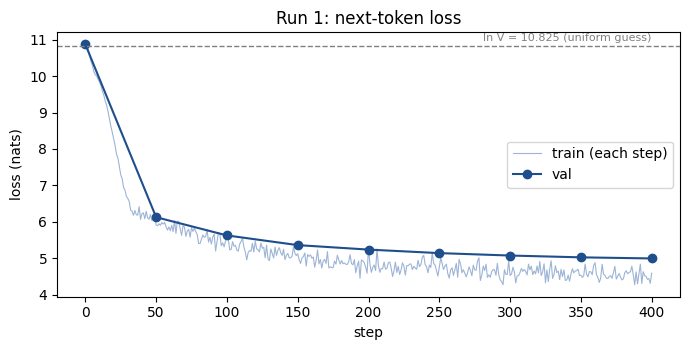

In [12]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(range(1, STEPS + 1), [l[0] for l in h1["step_loss"]], color="#9db4d6", lw=0.8, label="train (each step)")
ax.plot(h1["step"], h1["val"][1], "o-", color="#1f4e8c", label="val")
ax.axhline(math.log(V), color="grey", ls="--", lw=1)
ax.text(STEPS, math.log(V) + 0.15, "ln V = 10.825 (uniform guess)", ha="right", color="grey", fontsize=8)
ax.set_xlabel("step"); ax.set_ylabel("loss (nats)"); ax.set_title("Run 1: next-token loss")
ax.legend(); fig.tight_layout(); fig.savefig("figures/run1_loss.png", dpi=130); plt.show()

## 1.6 Padding mask

Four speeches of different lengths are padded to the longest one. GPT-2 has no pad token, so `<|endoftext|>`
is used as the filler. The mask is built from the **lengths**, never from "token == pad", because the same id
can occur as a real token.

In [13]:
model.eval()
speeches = [s for s in val_text.split("\n\n") if s.strip()]
picks = [s for s in speeches if 12 <= len(enc.encode_ordinary(s)) <= 70][:4]
seqs  = [enc.encode_ordinary(s) for s in picks]
lens  = torch.tensor([len(s) for s in seqs])
L     = int(lens.max())
batch = torch.full((len(seqs), L), EOT, dtype=torch.long)
for i, s in enumerate(seqs):
    batch[i, :len(s)] = torch.tensor(s)
batch = batch.to(device)
real = (torch.arange(L)[None, :] < lens[:, None]).to(device)        # [B, L]: True = a real token
print("lengths:", lens.tolist(), "-> padded to", L, "| batch", list(batch.shape), "| mask", list(real.shape))

with torch.no_grad():
    logits = model.output_head(model(batch))
    loss_all,  n_all  = lm_loss(logits, batch)                   # pads counted as targets
    loss_mask, n_mask = lm_loss(logits, batch, target_mask=real) # pads ignored
    per_tok = F.cross_entropy(logits[:, :-1].reshape(-1, V), batch[:, 1:].reshape(-1), reduction="none").view(len(seqs), L - 1)
    wrong_denominator = (per_tok * real[:, 1:]).sum().item() / (len(seqs) * (L - 1))
    pad_targets = ~real[:, 1:]
    # reference: each speech on its own, no padding at all
    alone = [F.cross_entropy(model.output_head(model(torch.tensor([s], device=device)))[0, :-1], torch.tensor(s[1:], device=device), reduction="sum").item() for s in seqs]
reference = sum(alone) / sum(len(s) - 1 for s in seqs)

print(f"\ncontributing targets: {n_all} with pads  ->  {n_mask} with the mask  ({n_all - n_mask} pad targets removed)")
print(f"loss, pads counted               : {loss_all.item():.4f}")
print(f"loss, pads masked                : {loss_mask.item():.4f}")
print(f"loss, masked but / (B x (T-1))   : {wrong_denominator:.4f}   <- right mask, wrong denominator")
print(f"each speech alone, no padding    : {reference:.4f}   (should equal 'pads masked')")
print(f"\nmean loss on the pad targets alone: {per_tok[pad_targets].mean().item():.3f}  vs real targets {per_tok[~pad_targets].mean().item():.3f}")
RESULTS.update(pad_n_with=n_all, pad_n_masked=n_mask, pad_loss_with=loss_all.item(),
               pad_loss_masked=loss_mask.item(), pad_loss_wrong_denominator=wrong_denominator,
               pad_reference=reference)
model.train();

lengths: [12, 18, 31, 29] -> padded to 31 | batch [4, 31] | mask [4, 31]

contributing targets: 120 with pads  ->  86 with the mask  (34 pad targets removed)
loss, pads counted               : 8.2686
loss, pads masked                : 4.5091
loss, masked but / (B x (T-1))   : 3.2315   <- right mask, wrong denominator
each speech alone, no padding    : 4.5091   (should equal 'pads masked')

mean loss on the pad targets alone: 17.778  vs real targets 4.509


## 1.7 Two documents in one sequence

Two unrelated speeches, taken from far apart in the validation text, are packed into one sequence. The pair at
the join, *(last token of A → first token of B)*, is a prediction nothing could make. Session 6's packing puts
an EOS token at that point, and then the pair *(EOS → first token of B)* is the one to mask. Our training text
has no EOS, so the documents are joined directly.

Four versions of the loss:

1. **no mask**
2. **loss mask at the boundary**: drops the one impossible target
3. **loss mask + document-aware attention + reset position ids**: B's tokens can no longer *see* A either
4. **reference**: A and B run separately (version 3 should match it exactly)

In [14]:
model.eval()
long_speeches = [s for s in speeches if 30 <= len(enc.encode_ordinary(s)) <= 60]
docA, docB = long_speeches[3], long_speeches[-3]                 # far apart in the play
A, Bd = enc.encode_ordinary(docA), enc.encode_ordinary(docB)
seq = torch.tensor([A + Bd], device=device)
T2, j = seq.shape[1], len(A)                                     # j = index of B's first token
print(f"A: {len(A)} tokens, ends  ...{enc.decode(A[-6:])!r}")
print(f"B: {len(Bd)} tokens, starts {enc.decode(Bd[:6])!r}...")
print(f"packed: {list(seq.shape)}; the boundary pair is position {j - 1} {tok(A[-1])} -> target {j} {tok(Bd[0])}\n")

boundary = torch.ones_like(seq, dtype=torch.bool); boundary[0, j] = False
doc_id = torch.tensor([0] * len(A) + [1] * len(Bd), device=device)
causal = torch.ones(T2, T2, dtype=torch.bool, device=device).tril()
doc_attn = (causal & (doc_id[:, None] == doc_id[None, :]))[None, None]   # [1, 1, T, T]
pos_reset = torch.tensor(list(range(len(A))) + list(range(len(Bd))), device=device)

def per_token(logits, x):
    return F.cross_entropy(logits[0, :-1], x[0, 1:], reduction="none")

with torch.no_grad():
    lg_plain = model.output_head(model(seq))
    lg_doc   = model.output_head(model(seq, attn_mask=doc_attn, pos=pos_reset))
    l_plain, n1 = lm_loss(lg_plain, seq)
    l_bmask, n2 = lm_loss(lg_plain, seq, target_mask=boundary)
    l_doc,   n3 = lm_loss(lg_doc,   seq, target_mask=boundary)
    sA = per_token(model.output_head(model(torch.tensor([A], device=device))), torch.tensor([A], device=device))
    sB = per_token(model.output_head(model(torch.tensor([Bd], device=device))), torch.tensor([Bd], device=device))
    l_ref = (sA.sum() + sB.sum()).item() / (len(sA) + len(sB))
    pt_plain, pt_doc = per_token(lg_plain, seq), per_token(lg_doc, seq)

x_b = pt_plain[j - 1].item()
print(f"loss of the boundary pair itself: {x_b:.3f} nats   (mean over the other pairs: {(pt_plain.sum().item() - x_b) / (n1 - 1):.3f})\n")
print(f"1. no mask                        : {l_plain.item():.4f}   ({n1} targets)")
print(f"2. boundary loss mask             : {l_bmask.item():.4f}   ({n2} targets)  "
      f"= ({pt_plain.sum().item():.2f} - {x_b:.2f}) / ({n1} - 1)")
print(f"3. + document-aware attention     : {l_doc.item():.4f}   ({n3} targets)")
print(f"4. A and B run separately         : {l_ref:.4f}")
print(f"\nB's own tokens (B predicting B):  seeing A {pt_plain[j:].mean().item():.4f}  |  "
      f"not seeing A {pt_doc[j:].mean().item():.4f}  |  B alone {sB.mean().item():.4f}")
print(f"max |version 3 - separate| per token: {max((pt_doc[:j-1] - sA).abs().max().item(), (pt_doc[j:] - sB).abs().max().item()):.2e}")
RESULTS.update(doc_loss_nomask=l_plain.item(), doc_loss_boundary_mask=l_bmask.item(), doc_loss_docattn=l_doc.item(),
               doc_loss_separate=l_ref, doc_boundary_pair_loss=x_b, doc_targets=[n1, n2])
model.train();

A: 53 tokens, ends  ...'aste and Dian sportful!'
B: 37 tokens, starts 'ALONSO:\nWhat'...
packed: [1, 90]; the boundary pair is position 52 '!' -> target 53 'AL'

loss of the boundary pair itself: 11.358 nats   (mean over the other pairs: 5.522)

1. no mask                        : 5.5872   (89 targets)
2. boundary loss mask             : 5.5216   (88 targets)  = (497.26 - 11.36) / (89 - 1)
3. + document-aware attention     : 5.4079   (88 targets)
4. A and B run separately         : 5.4079

B's own tokens (B predicting B):  seeing A 5.5305  |  not seeing A 5.2526  |  B alone 5.2526
max |version 3 - separate| per token: 1.43e-06


## 1.8 Peak memory: ordinary vs chunked cross-entropy

**Ordinary** computes all `N × V` logits at once and keeps them for the backward pass.

**Chunked** (written by hand below) takes 256 rows at a time, so only one `[256, V]` block exists at once. In
the backward pass it **recomputes** each block from the hidden states instead of storing it. Its gradient is
Section 5's `softmax − onehot`, written out directly.

There is a third variant, **loop**, that only chunks the forward pass. It is here to show that chunking alone
is not enough: autograd keeps every chunk for the backward pass, so most of the memory comes back.

In [15]:
%%writefile chunked_ce.py
# Chunked cross-entropy over the output head, written by hand.
# Only one [chunk, V] block of logits exists at a time; the backward pass recomputes each block.
import torch

IGNORE = -100

class ChunkedLinearCrossEntropy(torch.autograd.Function):
    @staticmethod
    def forward(ctx, h, W, y, chunk):
        # h [N, D] hidden states, W [V, D] head weight, y [N] targets (IGNORE = skip that row)
        valid = y != IGNORE
        n = valid.sum().clamp(min=1)
        y_safe = torch.where(valid, y, torch.zeros_like(y))
        lse = torch.empty(h.shape[0], dtype=torch.float32, device=h.device)
        total = torch.zeros((), dtype=torch.float32, device=h.device)
        for s in range(0, h.shape[0], chunk):
            z = (h[s:s + chunk] @ W.T).float()                      # [chunk, V]: the only big tensor
            lse[s:s + chunk] = torch.logsumexp(z, dim=-1)           # log Z of each row
            z_true = z.gather(1, y_safe[s:s + chunk, None]).squeeze(1)
            total += ((lse[s:s + chunk] - z_true) * valid[s:s + chunk]).sum()   # -log p = log Z - z_true
            del z
        ctx.save_for_backward(h, W, y_safe, valid, lse)             # all small: [N, D], [V, D], [N]
        ctx.chunk, ctx.n = chunk, n
        return total / n

    @staticmethod
    def backward(ctx, grad_out):
        h, W, y_safe, valid, lse = ctx.saved_tensors
        c, n = ctx.chunk, ctx.n
        dh, dW = torch.zeros_like(h), torch.zeros_like(W)
        for s in range(0, h.shape[0], c):
            hs = h[s:s + c]
            g = (hs @ W.T).float()                                  # recompute this block of logits
            g.sub_(lse[s:s + c, None]).exp_()                       # softmax, in place
            g[torch.arange(g.shape[0], device=g.device), y_safe[s:s + c]] -= 1.0   # softmax - onehot
            g.mul_(valid[s:s + c, None] * (grad_out / n))           # ignored rows get no gradient
            g = g.to(h.dtype)
            dh[s:s + c] = g @ W
            dW.addmm_(g.T, hs)
            del g
        return dh, dW, None, None

def chunked_cross_entropy(h, W, y, chunk=256):
    return ChunkedLinearCrossEntropy.apply(h, W, y, chunk)

Writing chunked_ce.py


In [16]:
# Correctness first: the same loss and the same gradients as F.cross_entropy, on real hidden states
# from the trained model and its real head, with every 7th target ignored to exercise the mask.
import importlib, chunked_ce; importlib.reload(chunked_ce)
from chunked_ce import chunked_cross_entropy

model.eval()
xb = get_batch(val_ids, 16, gen=torch.Generator().manual_seed(5))
with torch.no_grad():
    hid = model(xb)
h = hid[:, :-1].reshape(-1, cfg.d_model).clone().requires_grad_()
W = model.heads[0].weight.detach().clone().requires_grad_()
y = xb[:, 1:].reshape(-1).clone(); y[::7] = IGNORE

ref = F.cross_entropy(h @ W.T, y, ignore_index=IGNORE); ref.backward()
gh, gW = h.grad.clone(), W.grad.clone(); h.grad = W.grad = None
out = chunked_cross_entropy(h, W, y, chunk=256); out.backward()

rel = lambda a, b: ((a - b).abs().max() / b.abs().max()).item()
print(f"rows {h.shape[0]}, of which {(y != IGNORE).sum().item()} count")
print(f"loss     ordinary {ref.item():.7f}   chunked {out.item():.7f}   |diff| {abs(ref.item() - out.item()):.1e}")
print(f"grad h   max relative diff {rel(h.grad, gh):.1e}")
print(f"grad W   max relative diff {rel(W.grad, gW):.1e}")
print("(not bit-identical: the same sums are added in a different order, so float32 rounding differs)")
RESULTS["chunked_loss_diff"] = abs(ref.item() - out.item())
model.train();

rows 2032, of which 1741 count
loss     ordinary 5.0778432   chunked 5.0778432   |diff| 0.0e+00
grad h   max relative diff 5.0e-07
grad W   max relative diff 1.4e-06
(not bit-identical: the same sums are added in a different order, so float32 rounding differs)


In [17]:
%%writefile memprobe.py
# Peak extra memory of ONE cross-entropy forward + backward over the output head, in a fresh process
# (a fresh process so earlier peaks cannot hide this one).
# usage: python memprobe.py <ordinary|loop|chunked> N V D chunk   -> one JSON line
import sys, os, json, time, torch, torch.nn.functional as F
from chunked_ce import chunked_cross_entropy

variant, N, V, D, chunk = sys.argv[1], *map(int, sys.argv[2:6])
dev = "cuda" if torch.cuda.is_available() else "cpu"

def now_and_peak():
    if dev == "cuda":                                    # exact: the CUDA allocator's own counters
        return torch.cuda.memory_allocated(), torch.cuda.max_memory_allocated()
    if os.name == "nt":                                  # Windows: working set and its peak
        import psutil; m = psutil.Process().memory_info(); return m.wset, m.peak_wset
    import resource                                      # Linux: resident set and its peak
    now = int(open("/proc/self/statm").read().split()[1]) * os.sysconf("SC_PAGE_SIZE")
    return now, resource.getrusage(resource.RUSAGE_SELF).ru_maxrss * 1024

def loss_fn(h, W, y):
    if variant == "ordinary":     # all N x V logits at once
        return F.cross_entropy(h @ W.T, y)
    if variant == "loop":         # chunk the forward only: autograd still keeps every chunk
        return sum(F.cross_entropy(h[s:s + chunk] @ W.T, y[s:s + chunk], reduction="sum")
                   for s in range(0, N, chunk)) / N
    return chunked_cross_entropy(h, W, y, chunk)   # chunk forward AND recompute in backward

torch.manual_seed(0)
hw = torch.randn(8, D, device=dev, requires_grad=True)          # warm-up at a tiny size, so library
F.cross_entropy(hw @ hw.T, torch.zeros(8, dtype=torch.long, device=dev)).backward()   # start-up is not counted

h = torch.randn(N, D, device=dev, requires_grad=True)
W = (0.02 * torch.randn(V, D, device=dev)).requires_grad_()
y = torch.randint(0, V, (N,), device=dev)
if dev == "cuda":
    torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
before, _ = now_and_peak()
t0 = time.time()
loss = loss_fn(h, W, y); loss.backward()
if dev == "cuda":
    torch.cuda.synchronize()
secs = time.time() - t0
_, peak = now_and_peak()
print(json.dumps({"variant": variant, "N": N, "chunk": chunk, "device": dev,
                  "peak_extra_bytes": peak - before, "seconds": round(secs, 3), "loss": loss.item()}))

Writing memprobe.py


In [18]:
def probe(variant, N, chunk=256):
    r = subprocess.run([sys.executable, "memprobe.py", variant, str(N), str(V), str(cfg.d_model), str(chunk)],
                       capture_output=True, text=True, check=True)
    return json.loads(r.stdout.strip().splitlines()[-1])

MiB = 2 ** 20
rows = [probe(v, N) for N in (1024, 2048, 4096) for v in ("ordinary", "chunked")] + [probe("loop", 4096)]

print(f"device: {rows[0]['device']}  ({'CUDA allocator peak' if rows[0]['device'] == 'cuda' else 'peak working set of a fresh process'})")
print(f"V = {V:,}, D = {cfg.d_model}, float32, chunk = 256 rows\n")
print(f"{'variant':<10}{'N tokens':>9}{'logits if stored':>18}{'measured peak':>15}{'time':>8}{'loss':>9}")
for r in rows:
    print(f"{r['variant']:<10}{r['N']:>9,}{r['N'] * V * 4 / MiB:>14,.0f} MiB{r['peak_extra_bytes'] / MiB:>11,.0f} MiB"
          f"{r['seconds']:>7.2f}s{r['loss']:>9.4f}")

get = lambda v, N: next(r for r in rows if r["variant"] == v and r["N"] == N)
o, c, lp = get("ordinary", 4096), get("chunked", 4096), get("loop", 4096)
ratio = o["peak_extra_bytes"] / c["peak_extra_bytes"]
print(f"\nat N = 4,096 tokens: ordinary {o['peak_extra_bytes'] / MiB:,.0f} MiB vs chunked {c['peak_extra_bytes'] / MiB:,.0f} MiB"
      f" -> {ratio:.1f}x less;  forward-only chunking: {lp['peak_extra_bytes'] / MiB:,.0f} MiB")
RESULTS.update(mem_device=o["device"], mem_N=4096, mem_ordinary_MiB=o["peak_extra_bytes"] / MiB,
               mem_chunked_MiB=c["peak_extra_bytes"] / MiB, mem_loop_MiB=lp["peak_extra_bytes"] / MiB,
               mem_ratio=ratio, mem_rows=rows)

device: cuda  (CUDA allocator peak)
V = 50,257, D = 256, float32, chunk = 256 rows

variant    N tokens  logits if stored  measured peak    time     loss
ordinary      1,024           196 MiB        589 MiB   0.03s  10.8729
chunked       1,024           196 MiB        101 MiB   0.22s  10.8729
ordinary      2,048           393 MiB      1,178 MiB   0.07s  10.8829
chunked       2,048           393 MiB        102 MiB   0.27s  10.8829
ordinary      4,096           785 MiB      2,358 MiB   0.12s  10.8688
chunked       4,096           785 MiB        104 MiB   0.38s  10.8688
loop          4,096           785 MiB        904 MiB   0.13s  10.8688

at N = 4,096 tokens: ordinary 2,358 MiB vs chunked 104 MiB -> 22.6x less;  forward-only chunking: 904 MiB


# Part 2 — one extra head: predicting token *t+2*

Same trunk, plus a second `[V, D]` head. At position *t*, head 1 predicts token *t+1* and head 2 predicts
token *t+2*. The total loss is simply `L1 + L2`.

This run is controlled against Run 1: the trunk and head 1 start from the same weights (checked below), and
training sees the same batches in the same order. So the main difference between the runs is the extra head's
gradient flowing into the trunk.

In [19]:
torch.manual_seed(1337)
mtp = GPT(Config(n_out_heads=2)).to(device)
torch.manual_seed(1337); check = GPT(Config()).to(device)
same_start = all(torch.equal(check.state_dict()[k], mtp.state_dict()[k]) for k in check.state_dict())
print(f"parameters: {n_params(mtp):,} (Run 1: {n_params(check):,}; +{n_params(mtp) - n_params(check):,} = one more V x D head)")
print("trunk and head 1 start identical to Run 1:", same_start)
del check

h2 = train(mtp, shifts=(1, 2))

parameters: 43,450,368 (Run 1: 30,584,576; +12,865,792 = one more V x D head)
trunk and head 1 start identical to Run 1: True
step    0  t+1: train nan val 10.873  t+2: train nan val 10.832   (1s)
step   50  t+1: train 7.917 val 6.178  t+2: train 7.977 val 6.371   (9s)
step  100  t+1: train 5.778 val 5.706  t+2: train 6.092 val 6.104   (18s)
step  150  t+1: train 5.361 val 5.518  t+2: train 5.829 val 6.026   (27s)
step  200  t+1: train 5.069 val 5.364  t+2: train 5.648 val 5.958   (36s)
step  250  t+1: train 4.911 val 5.254  t+2: train 5.570 val 5.888   (45s)
step  300  t+1: train 4.786 val 5.188  t+2: train 5.497 val 5.867   (54s)
step  350  t+1: train 4.730 val 5.132  t+2: train 5.462 val 5.829   (64s)
step  400  t+1: train 4.667 val 5.096  t+2: train 5.413 val 5.807   (73s)


In [20]:
# A context-free baseline: predict every token from its frequency in the training text alone.
counts = torch.bincount(train_ids, minlength=V).double() + 1           # add-one so no token has p = 0
unigram = -(counts / counts.sum()).log()[val_ids].mean().item()

L1, L2 = h2["val"][1], h2["val"][2]
print(f"{'step':>5}{'Run 1 head t+1':>16}{'Run 2 head t+1':>16}{'Run 2 head t+2':>16}{'L1 + L2':>10}{'gap L2-L1':>11}")
for i, s in enumerate(h2["step"]):
    print(f"{s:>5}{v1[i]:>16.3f}{L1[i]:>16.3f}{L2[i]:>16.3f}{L1[i] + L2[i]:>10.3f}{L2[i] - L1[i]:>11.3f}")
print(f"\nunigram baseline (frequency only, no context): {unigram:.3f}")
bi = min(range(len(L2)), key=L2.__getitem__)
print(f"final: L1 {L1[-1]:.4f} | L2 {L2[-1]:.4f} | sum {L1[-1] + L2[-1]:.4f}   (val)")
print(f"best L2 {L2[bi]:.4f} at step {h2['step'][bi]};  Run 2 head 1 vs Run 1 at the end: {L1[-1] - v1[-1]:+.4f}")
RESULTS.update(p2_L1=L1[-1], p2_L2=L2[-1], p2_sum=L1[-1] + L2[-1], p2_best_L2=L2[bi], p2_best_L2_step=h2["step"][bi],
               p2_train_L1=h2["train"][1][-1], p2_train_L2=h2["train"][2][-1], p2_run1_L1=v1[-1],
               unigram=unigram, p2_gap=[b - a for a, b in zip(L1, L2)], p2_steps=h2["step"],
               p2_L1_curve=L1, p2_L2_curve=L2, run1_curve=v1)

 step  Run 1 head t+1  Run 2 head t+1  Run 2 head t+2   L1 + L2  gap L2-L1
    0          10.873          10.873          10.832    21.705     -0.041
   50           6.125           6.178           6.371    12.550      0.193
  100           5.625           5.706           6.104    11.810      0.398
  150           5.358           5.518           6.026    11.544      0.508
  200           5.235           5.364           5.958    11.322      0.594
  250           5.139           5.254           5.888    11.142      0.635
  300           5.072           5.188           5.867    11.055      0.679
  350           5.023           5.132           5.829    10.961      0.696
  400           4.992           5.096           5.807    10.903      0.710

unigram baseline (frequency only, no context): 6.510
final: L1 5.0964 | L2 5.8066 | sum 10.9031   (val)
best L2 5.8066 at step 400;  Run 2 head 1 vs Run 1 at the end: +0.1041


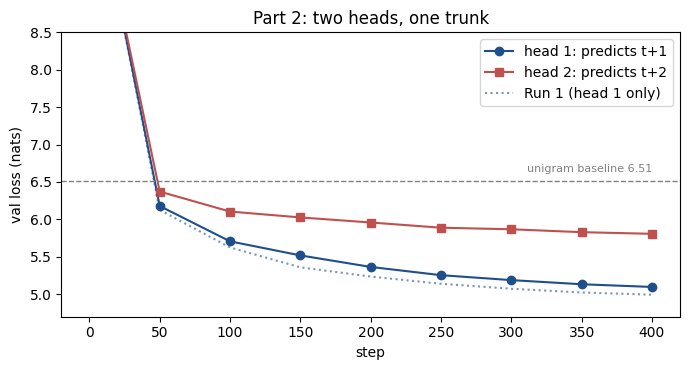

In [21]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(h2["step"], L1, "o-", color="#1f4e8c", label="head 1: predicts t+1")
ax.plot(h2["step"], L2, "s-", color="#c0504d", label="head 2: predicts t+2")
ax.plot(h1["step"], v1, ":", color="#1f4e8c", alpha=0.6, label="Run 1 (head 1 only)")
ax.axhline(unigram, color="grey", ls="--", lw=1)
ax.text(STEPS, unigram + 0.12, f"unigram baseline {unigram:.2f}", ha="right", color="grey", fontsize=8)
ax.set_ylim(top=8.5)
ax.set_xlabel("step"); ax.set_ylabel("val loss (nats)"); ax.set_title("Part 2: two heads, one trunk")
ax.legend(); fig.tight_layout(); fig.savefig("figures/part2_two_heads.png", dpi=130); plt.show()

# Part 3 — the bug the brief warns about

> *"A target shift in the incorrect direction can produce a beautiful loss curve. Print the strings."*

Below, the same model is trained with the shift **forgotten**: `cross_entropy(logits, tokens)`. Position *t*
is asked for token *t*, which it can already see. The curve is beautiful. Then the model is scored with the
correct harness.

what the strings check would have shown (position t: input -> target):
   0: 'O'          -> 'O'            <- the answer is the input
   1: ':'          -> ':'            <- the answer is the input
   2: '\n'         -> '\n'           <- the answer is the input
   3: 'Be'         -> 'Be'           <- the answer is the input
   4: ' collected' -> ' collected'   <- the answer is the input

buggy training loss: step 1 10.854 -> step 100 1.934
correct run, same steps: step 1 10.868 -> step 100 5.621

the buggy model scored with the CORRECT harness: val loss 9.490 (untrained model: 10.873, ln V = 10.825)


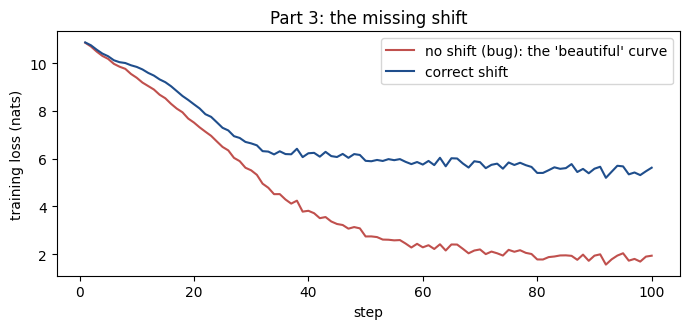

In [22]:
def no_shift(m, xb):                              # THE BUG: logits and targets are not offset
    return [F.cross_entropy(m.output_head(m(xb)).reshape(-1, V), xb.reshape(-1))]

BUG_STEPS = 100
torch.manual_seed(1337)
bug = GPT(Config()).to(device)
hb = train(bug, steps=BUG_STEPS, step_loss=no_shift, eval_every=BUG_STEPS, quiet=True)
bug_curve = [l[0] for l in hb["step_loss"]]
real_bug = evaluate(bug, val_ids)[1]

print("what the strings check would have shown (position t: input -> target):")
xs = get_batch(val_ids, 1, gen=torch.Generator().manual_seed(3))[0]
for t in range(5):
    print(f"   {t}: {tok(xs[t]):<12} -> {tok(xs[t]):<12}   <- the answer is the input")
print(f"\nbuggy training loss: step 1 {bug_curve[0]:.3f} -> step {BUG_STEPS} {bug_curve[-1]:.3f}")
print(f"correct run, same steps: step 1 {h1['step_loss'][0][0]:.3f} -> step {BUG_STEPS} {h1['step_loss'][BUG_STEPS - 1][0]:.3f}")
print(f"\nthe buggy model scored with the CORRECT harness: val loss {real_bug:.3f} "
      f"(untrained model: {init_val:.3f}, ln V = {math.log(V):.3f})")
RESULTS.update(bug_start=bug_curve[0], bug_end=bug_curve[-1], bug_real_val=real_bug,
               correct_at_bug_steps=h1["step_loss"][BUG_STEPS - 1][0])

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(range(1, BUG_STEPS + 1), bug_curve, color="#c0504d", label="no shift (bug): the 'beautiful' curve")
ax.plot(range(1, BUG_STEPS + 1), [l[0] for l in h1["step_loss"][:BUG_STEPS]], color="#1f4e8c", label="correct shift")
ax.set_xlabel("step"); ax.set_ylabel("training loss (nats)"); ax.set_title("Part 3: the missing shift")
ax.legend(); fig.tight_layout(); fig.savefig("figures/part3_missing_shift.png", dpi=130); plt.show()
del bug

## Summary — every number above, in one place

In [23]:
R = RESULTS
lines = [
    ("1. shift check (target at t == input at t+1)", f"{R['shift_check']}"),
    ("2. targets counted: pads in -> pads masked", f"{R['pad_n_with']} -> {R['pad_n_masked']}"),
    ("   loss: pads in / masked / wrong denominator", f"{R['pad_loss_with']:.4f} / {R['pad_loss_masked']:.4f} / {R['pad_loss_wrong_denominator']:.4f}"),
    ("3. packed docs: loss no mask -> boundary masked", f"{R['doc_loss_nomask']:.4f} -> {R['doc_loss_boundary_mask']:.4f}"),
    ("   + document-aware attention / run separately", f"{R['doc_loss_docattn']:.4f} / {R['doc_loss_separate']:.4f}"),
    ("4. untrained perplexity vs V", f"{R['init_ppl']:,.0f} vs {V:,} (loss {R['init_loss']:.4f} vs ln V {R['ln_V']:.4f})"),
    ("5. parameters untied / tied", f"{R['params_untied']:,} / {R['params_tied']:,}"),
    ("6. peak memory ordinary / chunked (N=4,096)", f"{R['mem_ordinary_MiB']:,.0f} MiB / {R['mem_chunked_MiB']:,.0f} MiB  ({R['mem_device']})"),
    ("7. ratio", f"{R['mem_ratio']:.1f}x"),
    ("Run 1 val loss (final)", f"{R['run1_final_val']:.4f}  (perplexity {R['run1_final_ppl']:.1f})"),
    ("Part 2 val: L1 (t+1) / L2 (t+2) / sum", f"{R['p2_L1']:.4f} / {R['p2_L2']:.4f} / {R['p2_sum']:.4f}"),
    ("Part 3 missing shift: train loss -> real val loss", f"{R['bug_end']:.3f} -> {R['bug_real_val']:.3f}"),
]
for k, v in lines:
    print(f"{k:<50} {v}")
with open("results.json", "w") as f:
    json.dump({k: v for k, v in R.items()}, f, indent=1)

1. shift check (target at t == input at t+1)       True
2. targets counted: pads in -> pads masked         120 -> 86
   loss: pads in / masked / wrong denominator      8.2686 / 4.5091 / 3.2315
3. packed docs: loss no mask -> boundary masked    5.5872 -> 5.5216
   + document-aware attention / run separately     5.4079 / 5.4079
4. untrained perplexity vs V                       52,743 vs 50,257 (loss 10.8732 vs ln V 10.8249)
5. parameters untied / tied                        30,584,576 / 17,718,784
6. peak memory ordinary / chunked (N=4,096)        2,358 MiB / 104 MiB  (cuda)
7. ratio                                           22.6x
Run 1 val loss (final)                             4.9924  (perplexity 147.3)
Part 2 val: L1 (t+1) / L2 (t+2) / sum              5.0964 / 5.8066 / 10.9031
Part 3 missing shift: train loss -> real val loss  1.934 -> 9.490
